# 01 · What exposure bias looks like in the data

**Question.** Clicks only happen on items a user was shown. How different is the logged
world from the world where every item is shown at random, and how extreme are the
weights a popularity-based exposure model implies?

**Why these datasets.** Yahoo! R3 and Coat each have two parts: ratings on items users
chose themselves (the logged data, missing not at random) and ratings on items assigned
uniformly at random (exploration traffic). In the second part exposure is guaranteed by
design, so a rating of 4 or 5 directly measures relevance, and it can serve as an unbiased
test set. Training only ever sees the first part.

Notation. `Y = O · R`: a positive label (click) needs exposure `O` and relevance `R`.
`θ̂_i = (n_i / max n)^η` is the paper's estimate of the exposure propensity θ (Eq. 12), with `n_i` the number
of training positives of item `i`.

In [1]:
import sys

sys.path[:0] = ["../src", "src"]  # from notebooks/ or from the repo root

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import AQUA, BLUE, MPL, ORANGE, RESULTS, THRESHOLD
from data import load, theta

plt.rcParams.update(MPL)
RESULTS.mkdir(exist_ok=True)
DATASETS = {"yahoo": "Yahoo! R3", "coat": "Coat"}
data = {k: load(k) for k in DATASETS}
out = []


def show(title, df, fmt=None):
    text = df.to_markdown(floatfmt=fmt) if fmt else df.to_markdown(disable_numparse=True)
    out.append(f"### {title}\n\n{text}\n")
    print(f"{title}\n{text}\n")

## 1. The two rating distributions

Users rate what they like. Self-selected ratings shift towards 4 and 5 (share with rating ≥ 4:
40% against 9% on Yahoo, 27% against 18.5% on Coat), although 1 star stays the most common rating.
Ratings on randomly assigned items pile up at 1. Every model below trains on the first
distribution and is tested on the second.

Share of ratings by star
|                             |   1 stars |   2 stars |   3 stars |   4 stars |   5 stars |
|:----------------------------|----------:|----------:|----------:|----------:|----------:|
| Yahoo! R3, self-selected    |     0.314 |     0.127 |     0.158 |     0.156 |     0.246 |
| Yahoo! R3, uniform exposure |     0.526 |     0.242 |     0.144 |     0.062 |     0.026 |
| Coat, self-selected         |     0.273 |     0.206 |     0.247 |     0.183 |     0.091 |
| Coat, uniform exposure      |     0.405 |     0.194 |     0.216 |     0.138 |     0.047 |



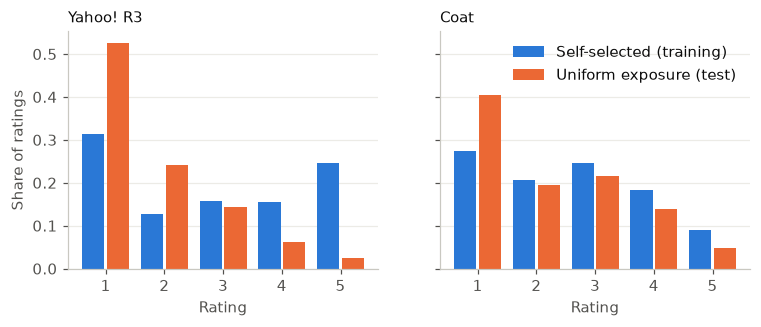

In [2]:
rows, fig_data = {}, {}
for k, name in DATASETS.items():
    d = data[k]
    for part, r in (("self-selected", d.train[:, 2]), ("uniform exposure", d.rand[:, 2])):
        share = np.bincount(r, minlength=6)[1:] / len(r)
        rows[f"{name}, {part}"] = share
        fig_data[(k, part)] = share
stars = pd.DataFrame(rows, index=[f"{s} stars" for s in range(1, 6)]).T
show("Share of ratings by star", stars, ".3f")

fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for ax, (k, name) in zip(axes, DATASETS.items()):
    x = np.arange(1, 6)
    ax.bar(x - 0.21, fig_data[(k, "self-selected")], 0.38, color=BLUE, label="Self-selected (training)")
    ax.bar(x + 0.21, fig_data[(k, "uniform exposure")], 0.38, color=ORANGE, label="Uniform exposure (test)")
    ax.set_title(name)
    ax.set_xlabel("Rating")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of ratings")
axes[1].legend(loc="upper right")
plt.savefig(RESULTS / "01_rating_shift.png")
plt.show()

## 2. Size, imbalance and the split

Training labels are extremely sparse: every pair that is not a training positive is
*unlabelled*, and the objective sums over all of them. The label frequency
`c* = P(Y=1) / P(R=1)` compares the click rate over all pairs to the relevance rate
measured on the small uniform slice (`val_B`): most relevant pairs never produce a label.

In [3]:
rows = {}
for k, name in DATASETS.items():
    d = data[k]
    users_rated = np.bincount(d.train[:, 0], minlength=d.m)
    rated = np.zeros((d.m, d.n), bool)
    rated[d.train[:, 0], d.train[:, 1]] = True
    overlap = rated[d.rand[:, 0], d.rand[:, 1]]
    p_y = len(d.fit) / (d.m * d.n)
    p_r = d.val_b.R.sum() / d.val_b.M.sum()
    rows[name] = {
        "users": d.m, "items": d.n,
        "self-selected ratings": len(d.train),
        "ratings per user, min to max": f"{users_rated.min()} to {users_rated.max()}",
        f"self-selected share with rating >= {THRESHOLD}": f"{(d.train[:, 2] >= THRESHOLD).mean():.3f}",
        "uniform-exposure ratings": len(d.rand),
        f"uniform-exposure share with rating >= {THRESHOLD}": f"{(d.rand[:, 2] >= THRESHOLD).mean():.3f}",
        "training positives (fit)": len(d.fit), "held-out positives (val_A)": len(d.val),
        "training label density": f"{p_y:.4%}",
        "label frequency c* on val_B": f"{p_y / p_r:.3f}",
        "val_B users / rows / positives / users with a positive":
            f"{len(d.val_b.users)} / {d.val_b.M.sum()} / {int(d.val_b.R.sum())} / {(d.val_b.R.sum(1) > 0).sum()}",
        "test users / rows / positives / users with a positive":
            f"{len(d.test.users)} / {d.test.M.sum()} / {int(d.test.R.sum())} / {(d.test.R.sum(1) > 0).sum()}",
        "uniform-exposure cells also rated in training (removed if any)": f"{overlap.sum()} ({(d.rand[overlap, 2] >= THRESHOLD).sum()} positive)",
    }
show("Datasets and splits", pd.DataFrame(rows))

Datasets and splits
|                                                                | Yahoo! R3                  | Coat                   |
|:---------------------------------------------------------------|:---------------------------|:-----------------------|
| users                                                          | 15400                      | 290                    |
| items                                                          | 1000                       | 300                    |
| self-selected ratings                                          | 311704                     | 6960                   |
| ratings per user, min to max                                   | 10 to 648                  | 24 to 24               |
| self-selected share with rating >= 4                           | 0.401                      | 0.274                  |
| uniform-exposure ratings                                       | 54000                      | 4640                   |
| uniform-ex

Coat's overlap cells would let a model score test positives by memorising training labels
(about a tenth of the test positives), so they leave both `val_B` and test. Yahoo! R3 has none.

## 3. Popularity and the implied exposure weights

The paper estimates exposure from popularity alone. A hot item is assumed to be shown often,
and a positive on a cold item is up-weighted by `1 / θ̂_i`. Clipping (`θ̄ = max(θ̂, M)`) only
changes the objective when `M` exceeds the smallest non-zero `θ̂`, so the table shows that value.

Popularity concentration
|                                                                   | Yahoo! R3                                | Coat                                   |
|:------------------------------------------------------------------|:-----------------------------------------|:---------------------------------------|
| top 10% of items, share of positives                              | 53.7%                                    | 33.2%                                  |
| most-rated item, share of users who rated it                      | 36.0%                                    | 30.3%                                  |
| hottest item, share of users who rated it                         | 34.2%                                    | 28.6%                                  |
| hottest item, click rate / test relevance rate = implied exposure | 0.149 / 0.39 = 0.38 (18 of 46 test rows) | 0.169 / 0.43 = 0.39 (3 of 7 test rows) |
| items with no training positive                  

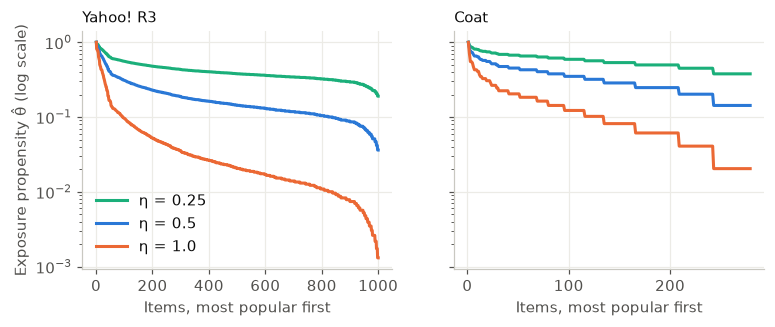

4581

In [4]:
rows, sel = [], {}
for k, name in DATASETS.items():
    d = data[k]
    sorted_n = np.sort(d.n_i)[::-1]
    rated_count = np.bincount(d.train[:, 1], minlength=d.n)
    hot = d.n_i.argmax()
    hot_rel = d.rand[(d.split == "test") & (d.rand[:, 1] == hot), 2] >= THRESHOLD
    sel[k] = {
        "top 10% of items, share of positives": f"{sorted_n[: d.n // 10].sum() / sorted_n.sum():.1%}",
        "most-rated item, share of users who rated it": f"{rated_count.max() / d.m:.1%}",
        "hottest item, share of users who rated it": f"{rated_count[hot] / d.m:.1%}",
        "hottest item, click rate / test relevance rate = implied exposure": f"{d.n_i[hot] / d.m:.3f} / {hot_rel.mean():.2f} = {d.n_i[hot] / d.m / hot_rel.mean():.2f} ({hot_rel.sum()} of {hot_rel.size} test rows)",
        "items with no training positive": f"{(d.n_i == 0).sum()}",
        "rare items: count, largest n_i": f"{d.rare.sum()}, {d.n_i[d.rare].max():.0f}",
        "Spearman(n_i, ratings per item)": f"{pd.DataFrame({'a': d.n_i, 'b': rated_count}).corr(method='spearman').iloc[0, 1]:.2f}",
    }
    for eta in (0.25, 0.5, 1.0):
        th = theta(d.n_i, eta)
        w = 1 / th[d.fit[:, 1]]
        rows.append({"dataset": name, "η": f"{eta:g}", "min non-zero θ̂": f"{th[th > 0].min():.4f}", "mean weight": f"{w.mean():.2f}", "max weight": f"{w.max():.1f}"})
show("Popularity concentration", pd.DataFrame(sel).rename(columns=DATASETS))
show("Exposure weights on training positives, by η", pd.DataFrame(rows).set_index("dataset"))

fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
for ax, (k, name) in zip(axes, DATASETS.items()):
    d = data[k]
    keep = np.sort(d.n_i[d.n_i > 0])[::-1]
    rank = np.arange(1, len(keep) + 1)
    for eta, color in ((0.25, AQUA), (0.5, BLUE), (1.0, ORANGE)):
        ax.plot(rank, (keep / keep.max()) ** eta, color=color, label=f"η = {eta}")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Items, most popular first")
axes[0].set_ylabel("Exposure propensity θ̂ (log scale)")
axes[0].legend(loc="lower left")
plt.savefig(RESULTS / "01_theta.png")
plt.show()

(RESULTS / "01_data.md").write_text("\n".join(out))

## Takeaways

* Selection shows in the raw ratings. The share of ratings ≥ 4 is 40.1% on self-selected Yahoo! items
  and 8.8% on randomly assigned ones (Coat: 27.4% and 18.5%). Models train on the first distribution
  and are tested on the second.
* Labels are sparse and concentrated. Positives cover 0.73% of Yahoo! pairs, the label frequency `c*` is
  about 0.09, and the top 10% of items hold 53.7% of positives (Coat: 1.97%, about 0.12, 33.2%).
* Popularity-based weights get extreme as η grows: the largest weight on a Yahoo! positive is 27.7 at
  η = 0.5 and 764.7 at η = 1. At η = 0.5 the smallest θ̂ is 0.036, so M = 0.01, the low end of the paper's
  range, changes nothing.
* `θ̂` is relative. Eq. 12 gives the hottest item `θ̂ = 1`. Under `Y = O · R`, that item's click rate of 0.149 and test relevance rate
  of 0.39 imply exposure of about 0.38 (18 of 46 test rows). So `θ̂` overstates exposure, and Rel-MF's `σ` should sit below the relevance rate
  at the population minimiser. Notebook 02 measures by how much. Rated shares cannot show this, since a rating needs exposure: the 34.2% who
  rated the hottest item and the 36.0% who rated the most-rated item, a different one, are floors.